# Interactive Customer Retention & Revenue Dashboard
**Objective:** Build an interactive decision-making dashboard to monitor customer churn rate, monthly revenue at risk, and retention trends across contract types and tenure.

**Design Principles Applied:**
1. **Top-Left Visual Hierarchy:** Primary KPIs (Churn Rate, Monthly Revenue at Risk, Average Tenure) are placed first with rounded numbers.
2. **High Data-Ink Ratio:** Removed chart gridlines, borders, and unnecessary decorative elements.
3. **Clear Visual Encodings:** Used bar and line charts instead of pie/area charts for accurate comparison.
4. **Interactive Filtering:** Added live dropdown controls to slice churn metrics by Contract Type and Internet Service.

In [1]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output


df = pd.read_csv("Telco-Customer-Churn.csv")

print(f"Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head(3)

Dataset loaded: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0.0)

df["Churn_Flag"] = (df["Churn"] == "Yes").astype(int)
df["Senior_Label"] = df["SeniorCitizen"].map({0: "Non-Senior", 1: "Senior"})

print("Missing values after cleaning:", df.isna().sum().sum())
print(f"Overall Churn Rate: {df['Churn_Flag'].mean() * 100:.1f}% ({df['Churn_Flag'].sum():,} of {len(df):,} customers)")

Missing values after cleaning: 0
Overall Churn Rate: 26.5% (1,869 of 7,043 customers)


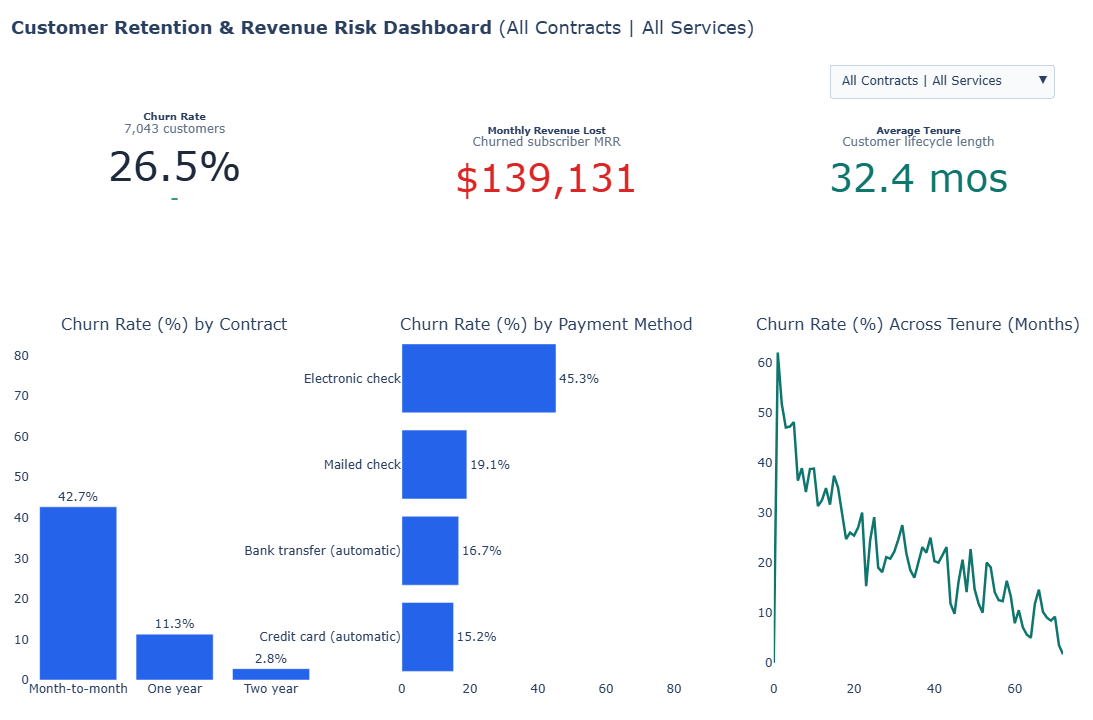

In [3]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Build filter combinations for native Plotly dropdowns
contracts = ["All Contracts"] + sorted(df["Contract"].unique().tolist())
internet_services = ["All Services"] + sorted(df["InternetService"].unique().tolist())

combinations = []
for c in contracts:
    for net in internet_services:
        sub = df.copy()
        if c != "All Contracts":
            sub = sub[sub["Contract"] == c]
        if net != "All Services":
            sub = sub[sub["InternetService"] == net]
        if not sub.empty:
            combinations.append((c, net, sub))

overall_churn = round(df["Churn_Flag"].mean() * 100, 1)

fig = make_subplots(
    rows=2, cols=3,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}, {"type": "indicator"}],
        [{"type": "bar"}, {"type": "bar"}, {"type": "scatter"}]
    ],
    row_heights=[0.28, 0.72],
    vertical_spacing=0.16,
    horizontal_spacing=0.08,
    subplot_titles=(
        "", "", "",
        "Churn Rate (%) by Contract",
        "Churn Rate (%) by Payment Method",
        "Churn Rate (%) Across Tenure (Months)"
    )
)

# Add 6 traces per filter combination (only the first combination is visible initially)
for idx, (c_label, net_label, sub) in enumerate(combinations):
    is_visible = (idx == 0)
    total_customers = len(sub)
    churn_rate = round(sub["Churn_Flag"].mean() * 100, 1)
    mrr_lost = sub.loc[sub["Churn"] == "Yes", "MonthlyCharges"].sum()
    avg_tenure = round(sub["tenure"].mean(), 1)

    contract_sum = (
        sub.groupby("Contract", as_index=False)["Churn_Flag"]
        .mean()
        .assign(Churn_Pct=lambda d: (d["Churn_Flag"] * 100).round(1))
        .sort_values("Churn_Pct", ascending=False)
    )
    payment_sum = (
        sub.groupby("PaymentMethod", as_index=False)["Churn_Flag"]
        .mean()
        .assign(Churn_Pct=lambda d: (d["Churn_Flag"] * 100).round(1))
        .sort_values("Churn_Pct", ascending=True)
    )
    tenure_sum = (
        sub.groupby("tenure", as_index=False)["Churn_Flag"]
        .mean()
        .assign(Churn_Pct=lambda d: (d["Churn_Flag"] * 100).round(1))
    )

    fig.add_trace(go.Indicator(
        mode="number+delta",
        value=churn_rate,
        visible=is_visible,
        number={"suffix": "%", "font": {"size": 40, "color": "#1E293B"}},
        delta={"reference": overall_churn, "relative": False, "valueformat": ".1f", "suffix": " pts vs avg"},
        title={"text": f"<b>Churn Rate</b><br><span style='font-size:12px;color:#64748B'>{total_customers:,} customers</span>"}
    ), row=1, col=1)

    fig.add_trace(go.Indicator(
        mode="number",
        value=mrr_lost,
        visible=is_visible,
        number={"prefix": "$", "valueformat": ",.0f", "font": {"size": 38, "color": "#DC2626"}},
        title={"text": "<b>Monthly Revenue Lost</b><br><span style='font-size:12px;color:#64748B'>Churned subscriber MRR</span>"}
    ), row=1, col=2)

    fig.add_trace(go.Indicator(
        mode="number",
        value=avg_tenure,
        visible=is_visible,
        number={"suffix": " mos", "font": {"size": 38, "color": "#0F766E"}},
        title={"text": "<b>Average Tenure</b><br><span style='font-size:12px;color:#64748B'>Customer lifecycle length</span>"}
    ), row=1, col=3)

    fig.add_trace(go.Bar(
        x=contract_sum["Contract"],
        y=contract_sum["Churn_Pct"],
        text=contract_sum["Churn_Pct"].astype(str) + "%",
        textposition="outside",
        marker_color="#2563EB",
        visible=is_visible,
        showlegend=False
    ), row=2, col=1)

    fig.add_trace(go.Bar(
        x=payment_sum["Churn_Pct"],
        y=payment_sum["PaymentMethod"],
        orientation="h",
        text=payment_sum["Churn_Pct"].astype(str) + "%",
        textposition="outside",
        marker_color="#2563EB",
        visible=is_visible,
        showlegend=False
    ), row=2, col=2)

    fig.add_trace(go.Scatter(
        x=tenure_sum["tenure"],
        y=tenure_sum["Churn_Pct"],
        mode="lines",
        line=dict(color="#0F766E", width=2.5),
        visible=is_visible,
        showlegend=False
    ), row=2, col=3)

# Build interactive dropdown menu inside Plotly
buttons = []
traces_per_view = 6
total_traces = len(combinations) * traces_per_view

for idx, (c_label, net_label, _) in enumerate(combinations):
    vis = [False] * total_traces
    for t in range(idx * traces_per_view, (idx + 1) * traces_per_view):
        vis[t] = True
    buttons.append(dict(
        label=f"{c_label} | {net_label}",
        method="update",
        args=[
            {"visible": vis},
            {"title.text": f"<b>Customer Retention & Revenue Risk Dashboard</b> ({c_label} | {net_label})"}
        ]
    ))

fig.update_layout(
    height=720,
    template="plotly_white",
    title=dict(
        text="<b>Customer Retention & Revenue Risk Dashboard</b> (All Contracts | All Services)",
        x=0.01,
        y=0.97,
        font=dict(size=18)
    ),
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        showactive=True,
        x=0.99,
        xanchor="right",
        y=1.08,
        yanchor="top",
        bgcolor="#F8FAFC",
        bordercolor="#CBD5E1"
    )],
    margin=dict(t=110, b=40, l=30, r=30)
)

fig.update_xaxes(showgrid=False, zeroline=False)
fig.update_yaxes(showgrid=False, zeroline=False)
fig.update_yaxes(range=[0, 85], row=2, col=1)
fig.update_xaxes(range=[0, 85], row=2, col=2)

fig.show()

## Key Actionable Insights & Recommendations
1. **Month-to-Month Contract Risk:** Customers on month-to-month contracts churn at **42.7%**, compared to **11.3%** on one-year and **2.8%** on two-year contracts. Offering targeted 1-year upgrade discounts during the first 6 months directly addresses the largest churn driver.
2. **Early Lifecycle Drop-Off:** Churn peaks in the first **1–5 months** of tenure and stabilizes after month 24, showing that onboarding check-ins in the first 90 days have the highest retention payoff.
3. **Payment Friction & Fiber Optic Segment:** Customers paying via **Electronic Check** (**45.3%** churn) and **Fiber Optic** subscribers (**41.9%** churn) represent the highest monthly recurring revenue at risk and should be prioritized for auto-pay incentives and service quality outreach.